# RFI: end-to-end example

Score the route freedom of a real area, step by step. Today the pipeline is three calls
(`parse_area` → `build_network` → `score_network`). When M3 lands, the last cell shows the
one-line `rfi(area)` call that wraps them.

Requires `pip install -e ".[notebook]"` and internet for the first download (cached afterwards).

In [1]:
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.collections import LineCollection
from matplotlib.patches import Ellipse
from scipy.sparse.csgraph import dijkstra

from rfi import constants as C
from rfi.metric import pair_score, score_network
from rfi.parser.area import parse_area
from rfi.parser.network import build_network

C.CACHE_DIR = str(Path.cwd().parent / "cache")  # share the repo-level cache when run from notebooks/
EPS, SEED = 0.1, 0

## 1. Area

Any of the four input forms works (see `rfi/parser/README.md`):

```python
parse_area("Le Marais, Paris")                                  # place name (needs internet)
parse_area((2.15, 41.38, 2.18, 41.40))                          # bbox (W, S, E, N)
parse_area({"point": (41.3910, 2.1650), "radius_m": 1500})      # point + radius
parse_area("area.geojson")                                      # polygon file
```

In [2]:
interior = parse_area({"point": (41.3910, 2.1650), "radius_m": 1500})
print(f"{interior.name}: {interior.area_km2:.2f} km², diameter {interior.diameter_m:.0f} m, {interior.utm_crs.name}")

point: 7.07 km², diameter 3000 m, WGS 84 / UTM zone 31N


## 2. Network

Downloads Overture segments and connectors for the interior plus a buffer, cleans them and builds the graph. The first run for a new area takes a minute or two; reruns read `cache/`.

In [3]:
built = build_network(interior, EPS)
print(built.meta)
pd.DataFrame(built.cleaning_stats).drop(columns="classes", errors="ignore").set_index("step")

13:35:54 INFO rfi.parser.network | download start cache=/Users/ivanesipov/Desktop/RFI/cache


13:35:54 INFO rfi.parser.network | cache hit folder=/Users/ivanesipov/Desktop/RFI/cache/bb6acec85a6992d2821397234b31cabf4b8329d0


13:35:54 INFO rfi.parser.network | download done elapsed_s=0.14 peak_rss_mb=375


13:35:54 INFO rfi.parser.network | filter start


13:35:54 INFO rfi.parser.network | walkable filter before=17420 after=9373 classes={'footway': 2620, 'residential': 1617, 'living_street': 794, 'tertiary': 722, 'steps': 719, 'secondary': 665, 'pedestrian': 654, 'cycleway': 522, 'service': 512, 'primary': 233, 'unknown': 225, 'path': 71, 'unclassified': 18, 'track': 1}


...

13:36:01 INFO rfi.parser.network | cleaning step=graph nodes=19892 edges=25043 length_km=700.66


13:36:01 INFO rfi.parser.network | cleaning step=isolated_removed nodes=18278 edges=23723 length_km=668.59


13:36:01 INFO rfi.parser.network | cleaning step=routing nodes=18278 edges=23710 length_km=668.59 interior_nodes=7200


{'overture_release': '2026-09-23.1', 'downloaded': '2026-10-18', 'n_nodes': 18278, 'n_edges': 23723}


,nodes,edges,length_km,connectors,interior_nodes
step,,,,,
download,NaN,17420,NaN,26703.0,NaN
walkable,NaN,9373,NaN,NaN,NaN
project,NaN,9373,700.65,NaN,NaN
split,NaN,25052,700.66,NaN,NaN
graph,19892.0,25043,700.66,NaN,NaN
isolated_removed,18278.0,23723,668.59,NaN,NaN
routing,18278.0,23710,668.59,NaN,7200.0


Text(0.5, 1.0, '18,278 nodes, 23,723 edges, 669 km')

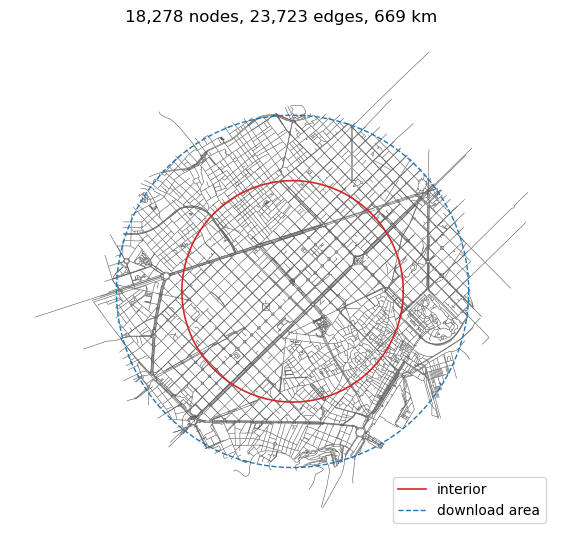

In [4]:
import pyproj
from shapely import ops

to_utm = pyproj.Transformer.from_crs(4326, interior.utm_crs, always_xy=True).transform
download_utm = ops.transform(to_utm, interior.download_geometry(EPS))

net, edges = built.net, built.edges
fig, ax = plt.subplots(figsize=(7, 7))
edges.plot(ax=ax, linewidth=0.4, color="0.35")
ax.plot(*interior.polygon_utm().exterior.xy, color="tab:red", lw=1.2, label="interior")
ax.plot(*download_utm.exterior.xy, color="tab:blue", ls="--", lw=1, label="download area")
ax.set_aspect("equal"); ax.set_axis_off(); ax.legend(loc="lower right")
ax.set_title(f"{len(net.xy):,} nodes, {len(net.u):,} edges, {net.length.sum() / 1000:.0f} km")

## 3. Score

`ellipse_ok` drops pairs whose reachable ellipse leaves the download area (the `boundary` exclusion).

In [5]:
res = score_network(net, eps=EPS, seed=SEED, ellipse_ok=built.ellipse_ok)
print(f"RFI = {res['score']:.3f}   (eps={EPS}, seed={SEED}, median circuity {res['circuity']:.2f})")
pd.DataFrame(res["bins"]).drop(columns="range_m").assign(
    bin_m=[f"{lo}-{hi}" for lo, hi in C.DIST_BINS]).set_index("bin_m").round(3)

13:36:02 INFO rfi.sampling | dijkstra start origins=150 nodes=18278


13:36:02 INFO rfi.sampling | dijkstra done elapsed_s=0.3 peak_rss_mb=573


13:36:02 INFO rfi.sampling | pairs kept=900 out_of_range=413 unreachable=0 too_circuitous=133 boundary=0


13:36:02 INFO rfi.metric | metric start pairs=900


13:36:03 INFO rfi.metric | metric done elapsed_s=1.07 peak_rss_mb=573


RFI = 0.404   (eps=0.1, seed=0, median circuity 1.22)


,bin,n_pairs,median_r,iqr_r,median_circuity,used
bin_m,,,,,,
300-750,0,300,0.434,0.205,1.252,True
750-1500,1,300,0.362,0.129,1.222,True
1500-3000,2,300,0.416,0.113,1.190,True


In [6]:
pd.DataFrame(res["diagnostics"]["bins"]).set_index("bin")  # exclusions per bin; column meanings: notebooks/METRICS.md

,candidates,unreachable,too_circuitous,boundary,kept
bin,,,,,
0,1770,0,107,0,300
1,4516,0,26,0,300
2,4476,0,0,0,300


## 4. Where is route freedom? (`edge_freedom`)

Share of in-ellipse trips for which each street is usable. Dark = streets that detours rarely use.

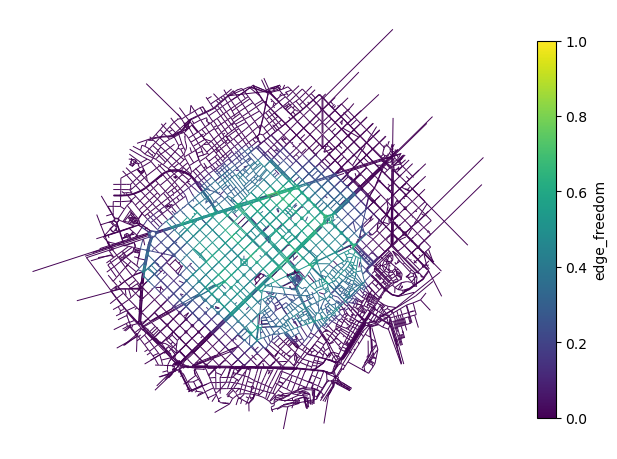

In [7]:
fig, ax = plt.subplots(figsize=(8, 7))
segs = np.stack([net.xy[net.u], net.xy[net.v]], axis=1)
lc = LineCollection(segs, linewidths=0.7, cmap="viridis")
lc.set_array(np.nan_to_num(res["edge_freedom"], nan=0.0)); lc.set_clim(0, 1)
ax.add_collection(lc); ax.autoscale(); ax.set_aspect("equal"); ax.set_axis_off()
fig.colorbar(lc, ax=ax, shrink=0.7, label="edge_freedom")

## 5. One trip in detail

Green = usable streets for this origin–destination pair within the budget, grey = inside the ellipse but not usable.

Text(0.5, 1.0, 'd*=1212 m   B=1333 m   U=12114   A=22070   r=0.549')

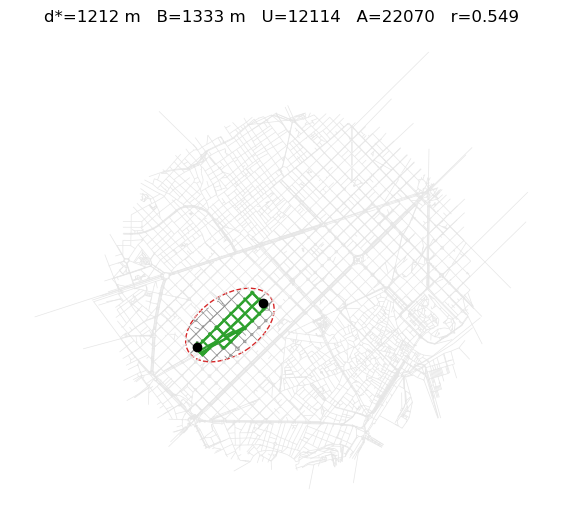

In [8]:
p = res["pairs"]
row = p[p["bin"] == 1].iloc[0]                      # first pair in the 750-1500 m bin
s, t = int(row["s"]), int(row["t"])
d = dijkstra(net.csr, directed=False, indices=[s, t])
U, A, usable, edge_in = pair_score(net, d[0], d[1], s, t, EPS)
B = (1 + EPS) * d[0][t]

fig, ax = plt.subplots(figsize=(7, 7))
col = np.where(usable, "tab:green", np.where(edge_in, "0.55", "0.9"))
ax.add_collection(LineCollection(segs, colors=col, linewidths=np.where(usable, 1.6, 0.5)))
(sx, sy), (tx, ty) = net.xy[s], net.xy[t]
c = np.hypot(tx - sx, ty - sy)
ax.add_patch(Ellipse(((sx + tx) / 2, (sy + ty) / 2), B, np.sqrt(B**2 - c**2),
                     angle=np.degrees(np.arctan2(ty - sy, tx - sx)), fill=False, ec="tab:red", ls="--"))
ax.plot([sx, tx], [sy, ty], "ko"); ax.autoscale(); ax.set_aspect("equal"); ax.set_axis_off()
ax.set_title(f"d*={d[0][t]:.0f} m   B={B:.0f} m   U={U:.0f}   A={A:.0f}   r={U / A:.3f}")

## 6. Target API (after M3)

Not available yet. Once `rfi()` and `Result` land (M3), everything above collapses to:

```python
import rfi

result = rfi.rfi({"point": (41.3910, 2.1650), "radius_m": 1500}, eps=0.1, seed=0)
result.score            # one number
result.save("results/eixample/")
```